# Candidate Comparison
This notebook compares the kinematic candidates from the Harris catalogue analysis with the age-metallicity candidates from the Krause21 and VandenBerg datasets.

In [16]:
import pandas as pd
import numpy as np

harris1 = pd.read_csv("HarrisPartI.csv")
Harris3 = pd.read_csv("HarrisPartIII.csv")
krause = pd.read_csv("Krause21.csv")
vanden = pd.read_csv("vandenBerg_table2.csv")

In [17]:
harris = pd.merge(harris1, Harris3, on="ID")

harris["sin_L"] = np.sin(np.radians(harris["L"]))

valid = harris[["sin_L", "v_LSR"]].dropna()

fit = np.polyfit(valid["sin_L"], valid["v_LSR"], 1)

harris["v_predicted"] = fit[0] * harris["sin_L"] + fit[1]
harris["v_residual"] = harris["v_LSR"] - harris["v_predicted"]

harris["candidate"] = (
    harris["v_residual"].abs() > 2 * harris["v_residual"].std()
)

harris_candidates = harris[harris["candidate"]].copy()
harris_candidates[["ID", "v_LSR", "v_residual"]]

,ID,v_LSR,v_residual
18,NGC 3201,482.9,363.656262
48,NGC 6101,357.0,276.626967
65,NGC 6287,-279.1,-277.394029
71,NGC 6333,239.8,252.973266
92,Djorg 1,-355.0,-360.593358
148,NGC 6934,-398.5,-301.085134
149,NGC 6981,-336.2,-264.721695
150,NGC 7006,-371.3,-260.754853


In [18]:
krause["fit"] = np.polyval(
    np.polyfit(krause["FeH"], krause['Age'], 1), krause["FeH"]
)

vanden["fit"] = np.polyval(
    np.polyfit(vanden["FeH"], vanden['Age'], 1), vanden["FeH"]
)

krause["residual"] = krause["Age"] - krause["fit"]
vanden["residual"] = vanden["Age"] - vanden["fit"]

krause["candidate"] = (
    krause["residual"].abs() > 2 * krause["residual"].std()
)

vanden["candidate"] = (
    vanden["residual"].abs() > 2 * vanden["residual"].std()
)

krause_candidates = krause[krause["candidate"]].copy()
vanden_candidates = vanden[vanden["candidate"]].copy()

print("Krause21 candidates:")
display(krause_candidates[["Object", "Age", "FeH", "residual"]])

print("vandenBerg candidates:")
display(vanden_candidates[["Name", "Age", "FeH", "residual"]])

Krause21 candidates:


,Object,Age,FeH,residual
4,NGC1851,7.64,-1.13,-4.323405
59,Terzan7,7.40,-0.12,-3.455415
60,Palomar12,8.60,-0.81,-3.012359


vandenBerg candidates:


,Name,Age,FeH,residual
23,M12,13.0,-1.33,1.230253
53,Pal12,9.0,-0.81,-2.231418


In [19]:
def clean_name(name):
    name = str(name).replace(" ", "").lower()

    if name.startswith("palomar"):
        name = name.replace("palomar", "pal")

    return name

In [20]:
harris_candidates["clean_name"] = harris_candidates["ID"].apply(clean_name)
krause_candidates["clean_name"] = krause_candidates["Object"].apply(clean_name)
vanden_candidates["clean_name"] = vanden_candidates["Name"].apply(clean_name)

In [21]:
age_candidates = set(krause_candidates["clean_name"]) | set(vanden_candidates["clean_name"])

common_candidates = harris_candidates[harris_candidates["clean_name"].isin(age_candidates)]

common_candidates[["ID", "v_LSR", "v_residual"]]
    

,ID,v_LSR,v_residual


In [22]:
harris["clean_name"] = harris["ID"].apply(clean_name)
krause["clean_name"] = krause["Object"].apply(clean_name)

harris_krause = pd.merge(
    harris, krause, on="clean_name", how="inner", suffixes=("_harris", "_krause")
)

harris_krause[["ID", "Object", "v_residual", "Age", "FeH", "residual"]].head(10)

,ID,Object,v_residual,Age,FeH,residual
0,NGC 104,NGC104,-123.816656,12.80,-0.76,1.242492
1,NGC 288,NGC288,6.073776,12.20,-1.32,0.028161
2,NGC 362,NGC362,111.747362,10.00,-1.26,-2.106017
3,NGC 1261,NGC1261,-65.305510,10.24,-1.08,-1.668554
4,NGC 1851,NGC1851,195.429562,7.64,-1.13,-4.323405
5,NGC 1904,NGC1904,101.135162,12.00,-1.58,-0.457064
6,NGC 2298,NGC2298,22.627311,12.40,-1.98,-0.495872
7,NGC 2808,NGC2808,-28.268246,11.20,-1.18,-0.818256
8,NGC 3201,NGC3201,363.656262,11.10,-1.51,-1.280272
9,NGC 4590,NGC4590,-201.104685,12.70,-2.27,-0.514007


In [24]:
harris_krause["velocity_score"] = harris_krause["v_residual"].abs() / harris_krause["v_residual"].std()

harris_krause["age_score"] = harris_krause["residual"].abs() / harris_krause["residual"].std()

harris_krause["combined_score"] = harris_krause["velocity_score"] + harris_krause["age_score"]

harris_krause[["ID", "velocity_score", "age_score", "combined_score"]].sort_values("combined_score", ascending=False).head(10)

,ID,velocity_score,age_score,combined_score
4,NGC 1851,1.449138,3.359257,4.808395
51,Terzan 7,1.343052,2.684835,4.027886
8,NGC 3201,2.696563,0.994763,3.691326
54,NGC 6934,2.232589,0.832811,3.065401
59,Pal 12,0.709523,2.340583,3.050106
55,NGC 6981,1.962949,0.894449,2.857398
38,NGC 6535,1.063376,1.460959,2.524335
2,NGC 362,0.828623,1.636362,2.464984
29,NGC 6304,0.791309,1.672241,2.463549
23,NGC 6144,1.381098,1.060500,2.441598


In [27]:
vanden["clean_name"] = vanden["Name"].apply(clean_name)

harris_vanden = pd.merge(
    harris, vanden, on="clean_name", how="inner", suffixes=("_harris", "_vanden")
)

harris_vanden[["ID", "Name_vanden", "v_residual", "Age", "FeH", "residual"]].head(10)

,ID,Name_vanden,v_residual,Age,FeH,residual
0,Pal 12,Pal12,95.685686,9.0,-0.81,-2.231418


In [28]:
vanden_candidate_names = set(vanden_candidates["clean_name"])

harris_krause["vanden_candidate"] = (harris_krause["clean_name"].isin(vanden_candidate_names))

comparison = harris_krause[["ID", "v_residual", "velocity_score", "age_score", "combined_score", "vanden_candidate"]].sort_values("combined_score", ascending=False)

comparison.head(10)

,ID,v_residual,velocity_score,age_score,combined_score,vanden_candidate
4,NGC 1851,195.429562,1.449138,3.359257,4.808395,False
51,Terzan 7,181.122863,1.343052,2.684835,4.027886,False
8,NGC 3201,363.656262,2.696563,0.994763,3.691326,False
54,NGC 6934,-301.085134,2.232589,0.832811,3.065401,False
59,Pal 12,95.685686,0.709523,2.340583,3.050106,True
55,NGC 6981,-264.721695,1.962949,0.894449,2.857398,False
38,NGC 6535,-143.405994,1.063376,1.460959,2.524335,False
2,NGC 362,111.747362,0.828623,1.636362,2.464984,False
29,NGC 6304,-106.715262,0.791309,1.672241,2.463549,False
23,NGC 6144,186.253683,1.381098,1.060500,2.441598,False


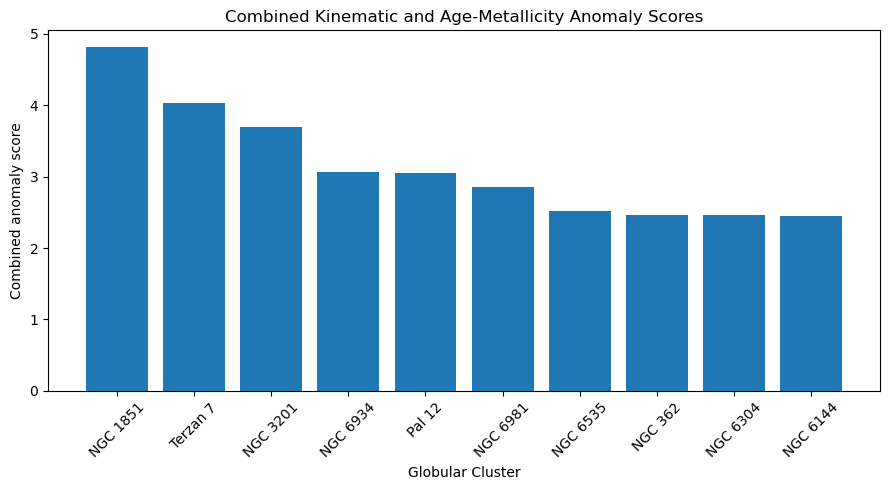

In [29]:
import matplotlib.pyplot as plt

top10 = comparison.head(10)

plt.figure(figsize=(9, 5))
plt.bar(top10["ID"], top10["combined_score"])

plt.xticks(rotation=45)
plt.ylabel("Combined anomaly score")
plt.xlabel("Globular Cluster")
plt.title("Combined Kinematic and Age-Metallicity Anomaly Scores")

plt.tight_layout()
plt.show()

## Preliminary comparison

The kinematic and age-metallicity analyses identify several globular clusters with unusual properties.
NGC 1851, Terzan 7, NGC 3201, NGC 3201, NGC 6934 and Pal 12 have the highest combined anomaly scores in this preliminary comparison.
The combined score is used only as an exploratory ranking of unusual clusters and does not directly measure the probability that a cluster was accreted. These candidates will be investigated further by comparing their kinematic, age-metallicity and spatial properties.